<a href="https://colab.research.google.com/github/naylaakas/PembelajaranMesin-2026/blob/main/JS13/datasetPBL/Praktikum3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf

# Load dataset cafes.csv (pengganti dummy data luas -> harga)
df_cafes = pd.read_csv('cafes.csv')

X = df_cafes[['review_count']]
y = df_cafes[['rating']]

# Normalisasi
scaler_X = StandardScaler()
scaler_y = StandardScaler()
X = scaler_X.fit_transform(X)
y = scaler_y.fit_transform(y)

# Split data (80:20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# --- Konfigurasi Awal (Learning Rate Default Adam = 0.001) ---
tf.random.set_seed(42)
model = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
    tf.keras.layers.Dense(1)
])

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mse')
history_001 = model.fit(X_train, y_train, epochs=100, verbose=0)

print("Prediksi (LR = 0.001):", model.predict(X_test[:5], verbose=0).flatten())
print(f"Train Loss (LR=0.001): {history_001.history['loss'][-1]:.4f} | Test Loss: {model.evaluate(X_test, y_test, verbose=0):.4f}")

# --- Tugas 4: Eksperimen Perubahan Learning Rate (0.01 dan 0.1) ---
for lr in [0.001, 0.01, 0.1]:
    tf.random.set_seed(42)
    m_lr = tf.keras.Sequential([
        tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
        tf.keras.layers.Dense(1)
    ])
    m_lr.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr), loss='mse')
    h_lr = m_lr.fit(X_train, y_train, epochs=100, verbose=0)
    train_loss = h_lr.history['loss'][-1]
    test_loss = m_lr.evaluate(X_test, y_test, verbose=0)
    print(f"Learning Rate = {lr:<6} -> Train MSE Loss: {train_loss:.4f} | Test MSE Loss: {test_loss:.4f}")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Prediksi (LR = 0.001): [ 0.17124583  0.20615928  0.04974505 -0.6364518  -0.00292918]
Train Loss (LR=0.001): 0.9143 | Test Loss: 0.4030
Learning Rate = 0.001  -> Train MSE Loss: 0.9145 | Test MSE Loss: 0.4049
Learning Rate = 0.01   -> Train MSE Loss: 0.8149 | Test MSE Loss: 0.3637
Learning Rate = 0.1    -> Train MSE Loss: 0.7776 | Test MSE Loss: 0.4830


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


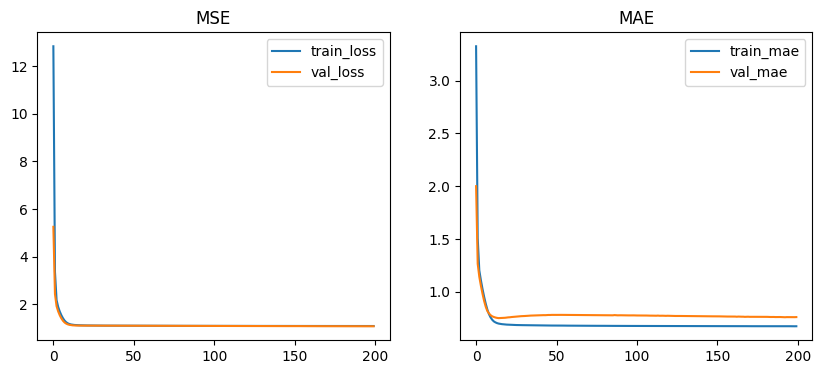

RMSE: 1.031898919078539


In [2]:
# MLP regresi (Keras) - Pengganti load_boston
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

# 1. Load dan gabungkan dataset
df_cafes = pd.read_csv('cafes.csv')
df_reviews = pd.read_csv('reviews.csv')
df = pd.merge(df_reviews, df_cafes, on='cafe_id', how='left', suffixes=('_review', '_cafe'))

X = df[['rating_cafe', 'review_count', 'likes', 'latitude', 'longitude']].values
y = df['rating_review'].values

# 2. Preprocess
scaler = StandardScaler()
Xs = scaler.fit_transform(X)
X_train, X_val, y_train, y_val = train_test_split(Xs, y, test_size=0.2, random_state=42)

# 3. Build model
model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(32, activation='relu'),
    Dense(1)
])
model.compile(optimizer=Adam(1e-3), loss='mse', metrics=['mae'])

# 4. Train
h = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=200, batch_size=32, verbose=0)

# 5. Plot
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(h.history['loss'], label='train_loss')
plt.plot(h.history['val_loss'], label='val_loss')
plt.legend()
plt.title('MSE')

plt.subplot(1, 2, 2)
plt.plot(h.history['mae'], label='train_mae')
plt.plot(h.history['val_mae'], label='val_mae')
plt.legend()
plt.title('MAE')
plt.show()

pred = model.predict(X_val, verbose=0)
print('RMSE:', np.sqrt(mean_squared_error(y_val, pred)))